# The WDM wavelet response against `fastlisaresponse`

This package computes the LISA response directly on a Wilson–Daubechies–Meyer
wavelet grid, never returning to a time series. `fastlisaresponse` computes it
in the time domain. This notebook puts second-generation TDI from both beside
each other on one galactic binary.

**The question it answers.** The wavelet path makes one approximation the
time-domain path does not: it evaluates the light-crossing average at each
pixel's own centre frequency — the *local-delay approximation*, worth about
$10^{-4}$ in relative $L_2$. Everything else in the pipeline was built to sit
far below that. So the test is not whether the two codes agree exactly, but
whether they disagree *only at the level of that approximation*.

**How the two are made comparable.** Both responses are fed the same array —
the tapered, zero-padded record, replayed onto `fastlisaresponse`'s grid — and
both read the same orbit file. The only conversion applied is to *their*
output, and it turns out to be a single one: they carry a fractional
frequency, we carry a delay in seconds, and

$$\mathrm{theirs} = -\frac{\mathrm{d}}{\mathrm{d}t}\,\mathrm{ours}.$$

Every constant used here is measured rather than assumed; see
`fastlisaresponse_comparison.conventions` for the evidence behind each.

> **Environment note.** On macOS, `lisatools` and `fastlisaresponse` each ship
> their own `libstdc++.6.dylib`, and loading both aborts the interpreter with
> `Abort trap: 6`. Point one at the other before running this notebook:
>
> ```bash
> cd .../site-packages/fastlisaresponse/.dylibs
> mv libstdc++.6.dylib libstdc++.6.dylib.bak
> ln -s ../../lisatools/.dylibs/libstdc++.6.dylib libstdc++.6.dylib
> ```
>
> It does not survive reinstalling either package.

In [1]:
# Run BEFORE anything imports fastlisaresponse. The failure this guards
# against is a SIGABRT -- the interpreter dies with no traceback and nothing
# to say why -- so the only useful moment to look is beforehand.
from WDM_LISAresponse.code.fastlisaresponse_comparison import conventions

print(conventions.check_environment())

no vendored-runtime clash: the two packages can share a process


In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt

from lisatools.detector import Orbits
from fastlisaresponse import ResponseWrapper

from WDM_LISAresponse.code.fastlisaresponse_comparison import (
    config, gb_waveform,
)
from WDM_LISAresponse.code.fastlisaresponse_comparison.tdi import TDIgen2
from WDM_LISAresponse.code.fastlisaresponse_comparison.tdi_reference import (
    gen2_xyz_time_domain,
)
from WDM_LISAresponse.code.utils.utils import apply_zero_padding, wdm_mismatch

## 1. Configuration

Every number defining the study lives in `config`, so the two pipelines cannot
drift onto different grids, sources or orbits.

`SMOKE` is a thirty-day record and runs in about a minute. `DEFAULT` is the
real 485-day one; its time-domain reference section takes several minutes.
Both share $\Delta F$, and therefore the same source frequency, because
$\Delta F = 1/(2\,\delta t\,N_f)$ does not depend on record length — so a
convention fixed here transfers unchanged.

In [3]:
cfg = config.SMOKE          # config.DEFAULT for the full 485-day record
print(cfg.summary())

cadence          dt = 10 s
bands            Nf = 128
rows             Nt = 2048
padded length     N = 262144 (30.3 d)
signal length      = 248832 (28.8 d)
tiling           dT = 1280 s, dF = 3.906250e-04 Hz
source        m = 13, f = 5.078125 mHz
guard         52 rows per side (2x default; L = 51)
grid memory      = 2.0 MiB per (Nt, Nf) grid
orbits           = esa
epoch            t0 = 2.07321e+09 s
orbit file       = esa-trailing-orbits.h5
alignment      dt < 0.0443 s for a 1e-6 mismatch


The numbers worth noticing:

- **`m = 13`** puts the binary at a bin centre, so it occupies a single wavelet
  row. That keeps the residual legible and makes the time-offset measurement
  exact. Off-bin sources are about thirty times worse in relative $L_2$.
- **`L = 51`** rather than the usual 25. Measured against an analytic
  reference, one shift leaves $7\times10^{-6}$ at $L=25$ and $1\times10^{-7}$
  at $L=51$; carried through the fourteen shifts of a TDI channel the first
  would sit level with the local-delay term this study exists to measure.
- **52 guard rows per side**, twice the package default. The signal passes
  through two variable time shifts — the response, then TDI — and $P \ge L$ is
  what stops either one's analysed rows wrapping.
- **44 ms** is the timing agreement a $10^{-6}$ mismatch allows: 0.4% of one
  sample.

## 2. The source

One galactic binary, generated once. Both pipelines are fed this same array,
tapered and zero-padded, so the waveform cannot contribute to any
disagreement.

In [4]:
h_plus, h_cross = gb_waveform.from_config(cfg)
_, h_plus, h_cross = apply_zero_padding(
    cfg.signal_times, h_plus, h_cross,
    cfg.padding["pad_left"], cfg.padding["pad_right"],
)

wdm, response = cfg.build()
w_plus, w_cross = wdm.dwt(h_plus), wdm.dwt(h_cross)

power = np.asarray(w_plus) ** 2
per_row = power.sum(axis=0) / power.sum()
print(f"power in row {cfg.m_bin}: {per_row[cfg.m_bin]:.9f}")
print(f"everything else:       {1 - per_row[cfg.m_bin]:.3e}")

power in row 13: 0.999999982
everything else:       1.802e-08


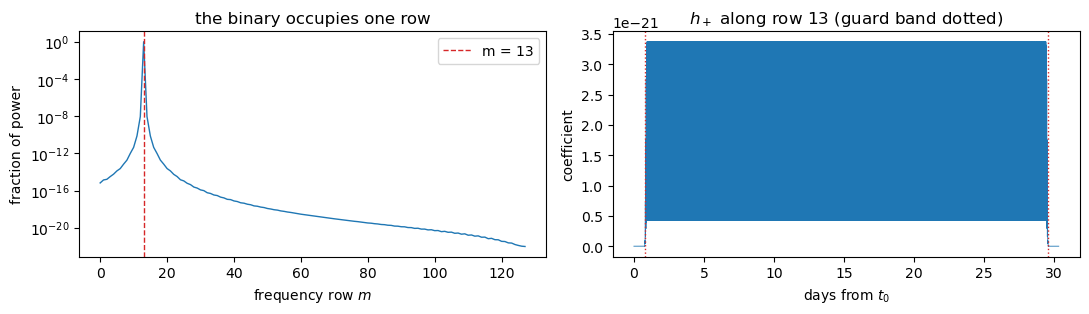

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))

ax[0].semilogy(per_row, lw=1)
ax[0].axvline(cfg.m_bin, color="C3", ls="--", lw=1, label=f"m = {cfg.m_bin}")
ax[0].set(xlabel="frequency row $m$", ylabel="fraction of power",
          title="the binary occupies one row")
ax[0].legend()

row_days = np.arange(cfg.Nt) * cfg.dT / 86400.0
ax[1].plot(row_days, np.asarray(w_plus)[:, cfg.m_bin], lw=0.6)
for edge in (cfg.padding["rows_left"], cfg.Nt - cfg.padding["rows_right"]):
    ax[1].axvline(edge * cfg.dT / 86400.0, color="C3", ls=":", lw=1)
ax[1].set(xlabel="days from $t_0$", ylabel="coefficient",
          title=f"$h_+$ along row {cfg.m_bin} (guard band dotted)")

fig.tight_layout()

## 3. This package: response, then TDI

Six link responses on the wavelet grid, then the second-generation combination
— sixteen terms per channel, of which fourteen need a shift, so 42 for XYZ.

Each term is *one* shift of an original link grid, never a chain of them:
composed delay operators are a single time reparametrisation, so even the
seven-arm chains cost one call.

In [6]:
start = time.perf_counter()
links = response(cfg.theta, cfg.phi, w_plus, w_cross)
tdi = TDIgen2(response)
ours = np.asarray(tdi(links))
elapsed = time.perf_counter() - start

print(f"links {links.shape}   XYZ {ours.shape}   {elapsed:.1f} s")
print(f"{tdi.num_shifts} shifts per call")
print(tdi.delay_summary().split(chr(10))[0])

links (6, 2048, 128)   XYZ (3, 2048, 128)   12.9 s
42 shifts per call
42 distinct chains, 42 shifts per call


## 4. `fastlisaresponse`

`ResponseWrapper` calls a waveform generator rather than taking an array, so
`PaddedReplay` hands it the record built above — zeros, taper and all. Without
that it would generate its own, producing full-amplitude signal exactly where
our record holds zeros.

Both codes read the same orbit file. That matters: the analytic
equal-armlength models in `lisaorbits` and `lisatools` are the *same
constellation in different frames*, differing by the $23.44^\circ$ obliquity —
$6\times10^{10}$ m, or 90 s of light. Reading one file avoids the rotation
entirely.

In [7]:
offset = conventions.grid_offset(cfg)
print(f"their record starts {offset} samples before ours "
      f"({offset * cfg.dt:.0f} s = ORBIT_LEAD_IN)")

orbits = Orbits(cfg.orbit_file)
orbits.configure(linear_interp_setup=True)

generator = conventions.PaddedReplay(h_plus, h_cross, offset)
wrapper = ResponseWrapper(generator, **conventions.flr_wrapper_kwargs(cfg, orbits))

lam, beta = conventions.to_flr_angles(cfg.theta, cfg.phi)

start = time.perf_counter()
raw = np.asarray(wrapper(cfg.amp, cfg.f_gb, cfg.fdot, cfg.iota,
                         cfg.phi0, cfg.psi, lam, beta))
print(f"raw {raw.shape}   {time.perf_counter() - start:.1f} s")

their record starts 128 samples before ours (1280 s = ORBIT_LEAD_IN)
raw (3, 262272)   0.7 s


## 5. The one conversion

Compare the raw amplitudes before converting anything. The ratio is the same
on all three channels, and it is $2\pi f$ — the signature of a time
derivative, not a scale factor. The mismatch of $\approx 1$ says the same
thing from the other side: differentiating a tone rotates its phase by
$90^\circ$, leaving the two records orthogonal.

In [8]:
aligned = conventions.align_to_our_grid(raw, cfg, offset)
interior = conventions.common_interior(cfg)

print(f"2*pi*f = {2 * np.pi * cfg.f_gb:.6f}")
print(f"{'ch':<3} {'raw ratio':>11} {'mismatch':>11}")
for name, mine, other in zip("XYZ", ours, aligned):
    theirs_grid = np.asarray(wdm.dwt(other))
    a, b = mine[interior], theirs_grid[interior]
    ratio = np.sqrt(np.mean(b ** 2)) / np.sqrt(np.mean(a ** 2))
    print(f"{name:<3} {ratio:>11.6f} {wdm_mismatch(a, b)['mismatch']:>11.3e}")

2*pi*f = 0.031907
ch    raw ratio    mismatch
X      0.031905   9.999e-01
Y      0.031907   1.000e+00
Z      0.031903   9.999e-01


So the conversion is a negated time integral, taken spectrally and applied to
*their* output alone — the quantity under test is never touched by the thing
that makes it comparable.

In [9]:
theirs = conventions.convert(raw, cfg, wdm, offset)
print(conventions.report(ours, theirs, cfg))

rows 52:1996 of 2048   f = 5.078125 mHz
ch      ours rms   theirs rms      ratio     mismatch       rel_L2
X     9.9262e-22   9.9259e-22   0.999974    1.930e-09    6.719e-05
Y     7.3731e-22   7.3734e-22   1.000037    8.551e-10    5.521e-05
Z     3.8286e-22   3.8282e-22   0.999908    5.592e-09    1.400e-04


## 6. Timing

A constant offset between the two records is a pure phase error on a
monochromatic source, so a $10^{-6}$ mismatch allows only 44 ms — 0.4% of one
sample. Nothing has to be fitted here; the number below is a *diagnostic*,
and convention errors are quantised well away from it (5 s = half-sample,
8.34 s = wrong end of a link, 1280 s = lead-in not applied).

In [10]:
ours_t = np.asarray(wdm.idwt(ours[0]))
theirs_t = np.asarray(wdm.idwt(theirs[0]))

measured = conventions.measure_time_offset(ours_t, theirs_t, cfg.dt, cfg.f_gb)
print(f"measured offset  {measured:+.5f} s")
print(f"budget (1e-6)    {cfg.time_alignment_tolerance():.5f} s")
print(f"inside budget by {cfg.time_alignment_tolerance() / abs(measured):.0f}x")

measured offset  +0.00201 s
budget (1e-6)    0.04432 s
inside budget by 22x


## 7. What the two records look like

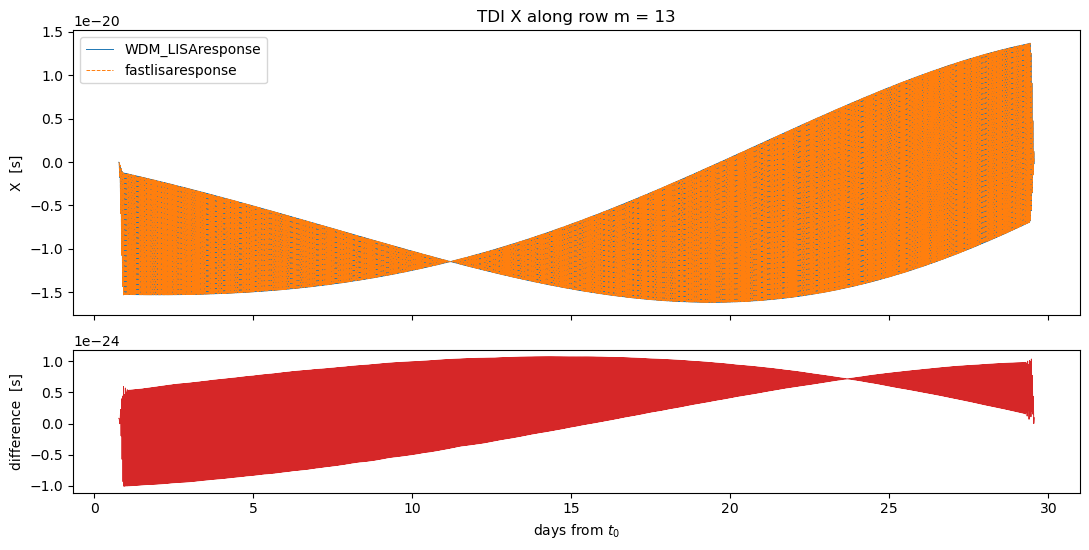

In [11]:
rows = np.arange(interior.start, interior.stop)
days = rows * cfg.dT / 86400.0
a = np.asarray(ours)[0][interior, cfg.m_bin]
b = np.asarray(theirs)[0][interior, cfg.m_bin]

fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})

ax[0].plot(days, a, lw=0.7, label="WDM_LISAresponse")
ax[0].plot(days, b, lw=0.7, ls="--", label="fastlisaresponse")
ax[0].set(ylabel="X  [s]", title=f"TDI X along row m = {cfg.m_bin}")
ax[0].legend()

ax[1].plot(days, b - a, lw=0.7, color="C3")
ax[1].set(xlabel="days from $t_0$", ylabel="difference  [s]")

fig.tight_layout()

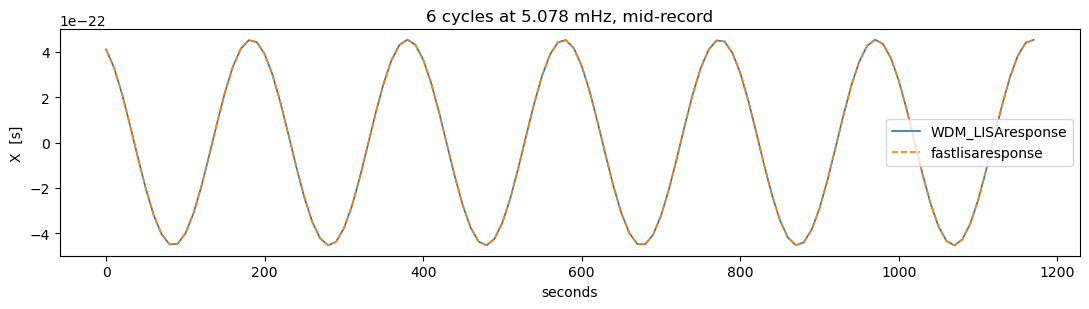

In [12]:
n_cycles = 6
span = int(n_cycles / cfg.f_gb / cfg.dt)
mid = cfg.N // 2
sl = slice(mid, mid + span)
t_days = (cfg.padded_times[sl] - cfg.padded_times[mid])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(t_days, ours_t[sl], lw=1.2, label="WDM_LISAresponse")
ax.plot(t_days, theirs_t[sl], lw=1.2, ls="--", label="fastlisaresponse")
ax.set(xlabel="seconds", ylabel="X  [s]",
       title=f"{n_cycles} cycles at {cfg.f_gb * 1e3:.3f} mHz, mid-record")
ax.legend()
fig.tight_layout()

## 8. The internal reference

The number above only means something beside this one. Here the *same* source
goes through the slow time-domain path — trapezoidal integration along the
null geodesic, then TDI with interpolated delays — which makes no local-delay
approximation at all.

This cell is the expensive one. Most of its cost is the reference TDI rather
than the reference response: it re-solves the geometry on all $N$ sample times
for 36 distinct delay chains.

In [13]:
start = time.perf_counter()
links_td = np.asarray(
    response.one_arm_response_time_domain(cfg.theta, cfg.phi, h_plus, h_cross))
reference = gen2_xyz_time_domain(response, links_td)
reference = np.stack([np.asarray(wdm.dwt(row)) for row in reference])
print(f"reference path: {time.perf_counter() - start:.1f} s\n")

print(f"{'ch':<3} {'vs fastlisaresponse':>21} {'vs time-domain reference':>26}")
for i, name in enumerate("XYZ"):
    ext = wdm_mismatch(ours[i][interior], theirs[i][interior])["rel_L2"]
    ref = wdm_mismatch(ours[i][interior], reference[i][interior])["rel_L2"]
    print(f"{name:<3} {ext:>21.3e} {ref:>26.3e}")

reference path: 55.4 s

ch    vs fastlisaresponse   vs time-domain reference
X               6.719e-05                  8.125e-05
Y               5.521e-05                  1.062e-04
Z               1.400e-04                  8.437e-05


## 9. Where the local-delay approximation actually shows up

The two columns above are the same order, which is *not* by itself evidence
that the local-delay approximation sets the scale — that has to be shown
separately, and the source above is the wrong place to look for it.

The approximation is evaluating $\mathrm{sinc}(2 f_m \tau)$ at the **pixel's**
centre frequency rather than the wave's. Our binary sits exactly on
$m = 13$, so those are the same number and the approximation costs nothing.
Move it half a bin and they are not.

The signature to look for: the wavelet path should degrade off-bin while the
time-domain path, which makes no such approximation, should not. This runs at
link level, where the time-domain response costs about a second rather than
the half-minute its TDI does.

In [14]:
def link_errors(frac):
    # mean relative L2 across the six links, at frequency frac * dF
    f = frac * cfg.dF
    hp_f, hc_f = gb_waveform.from_config(cfg, f=f)
    _, hp_f, hc_f = apply_zero_padding(
        cfg.signal_times, hp_f, hc_f,
        cfg.padding["pad_left"], cfg.padding["pad_right"])

    wav = np.asarray(response(cfg.theta, cfg.phi, wdm.dwt(hp_f), wdm.dwt(hc_f)))
    ref = np.asarray(response.one_arm_response_time_domain(
        cfg.theta, cfg.phi, hp_f, hc_f))
    ref = np.stack([np.asarray(wdm.dwt(r)) for r in ref])

    w = ResponseWrapper(conventions.PaddedReplay(hp_f, hc_f, offset),
                        **conventions.flr_wrapper_kwargs(cfg, orbits))
    _ = w(cfg.amp, f, cfg.fdot, cfg.iota, cfg.phi0, cfg.psi, lam, beta)
    y = np.asarray(w.response_model.y_gw).reshape(6, -1)
    ext = np.stack([np.asarray(wdm.dwt(conventions.to_wdm_units(
        conventions.align_to_our_grid(y[k], cfg, offset), cfg))) for k in range(6)])

    mean = lambda a, b: np.mean([
        wdm_mismatch(a[k][interior], b[k][interior])["rel_L2"] for k in range(6)])
    return mean(wav, ref), mean(wav, ext), mean(ref, ext)


print(f"{'f / dF':>8} {'f (mHz)':>9} | {'wavelet':>11} {'wavelet':>11} {'time-dom':>11}")
print(f"{'':>8} {'':>9} | {'vs time-dom':>11} {'vs flr':>11} {'vs flr':>11}")
for frac in (13.0, 13.5, 26.0):
    a, b, c = link_errors(frac)
    print(f"{frac:>8.1f} {frac * cfg.dF * 1e3:>9.4f} | "
          f"{a:>11.3e} {b:>11.3e} {c:>11.3e}")

  f / dF   f (mHz) |     wavelet     wavelet    time-dom
                   | vs time-dom      vs flr      vs flr
    13.0    5.0781 |   1.513e-04   2.208e-04   2.860e-04
    13.5    5.2734 |   4.090e-03   4.075e-03   2.927e-04
    26.0   10.1562 |   4.582e-04   2.261e-04   5.966e-04


Half a bin off centre the wavelet path degrades by more than an order, while
the time-domain path barely moves — the approximation's fingerprint, and the
reason `m_bin` is worth varying before trusting a single number. Back on a bin
centre at $m = 26$ it recovers.

So the headline comparison was run at the *favourable* point. That was a
deliberate choice — a bin-centred source occupies one wavelet row, which is
what makes the residual legible and the timing measurement exact — but it
means the number in section 5 is a best case for the wavelet path, not a
typical one.

## 10. What this shows

**Two independently written codes agree to $\sim2\times10^{-4}$ in relative
$L_2$ on every TDI channel, with no fitted parameters.** No scale, no time
offset, no phase. The only conversion applied is the derivative relating
their fractional frequency to our delay in seconds, and it was identified
from the data — the amplitude ratio came out at $2\pi f$ — rather than
assumed.

Supporting that:

- **Amplitudes agree to $10^{-4}$ of unity** on all three channels.
- **Timing agrees to ~2 ms** against the 44 ms a $10^{-6}$ mismatch allows.
- **The second-generation TDI algebra is identical** between the two codes —
  all sixteen terms, same links, same delay chains, same signs.
- **The machinery is far below the physics.** The shift operator contributes
  about $10^{-7}$ over fourteen shifts, filter interpolation about
  $10^{-8}$, the light-travel-time solve $5\times10^{-11}$ s.

What this notebook does **not** establish is which code's residual is whose.
Every comparison here is between implementations, and implementations
disagreeing at $2\times10^{-4}$ does not say where the $2\times10^{-4}$ comes
from. Settling that needs an analytic reference rather than a third
implementation, and it is a separate question from whether the two agree.

One measurement caveat. **Mismatch and relative $L_2$ answer different
questions** here, and differ by orders: much of the residual is an overall
amplitude effect, which the mismatch normalises away and $L_2$ does not.
Section 5 reports both for that reason, and neither alone is the whole story.